# Wykrywanie śladów w plikach FITS — wprowadzenie

Notebook dla osób, które pierwszy raz mają do czynienia z danymi z teleskopu. Po przejściu przez niego powinieneś wiedzieć:

1. **czym jest plik FITS** i jak go czytać w Pythonie,
2. **czym jest nagłówek WCS** i jak zamienić piksel na współrzędne na niebie,
3. **jak otwierać ramki w DS9** (instalacja + gotowe komendy + pliki regionów),
4. **jak wyglądają ślady** — od przypadków, gdzie nic nie widać, po te oczywiste,
5. **po co usuwamy gwiazdy** i jak to wygląda przed/po,
6. **czym jest stackowanie (shift-and-stack)**, co daje i **dlaczego jest tak drogie**.

### Czym jest „ślad”?
Satelita (albo inny szybki obiekt) w trakcie ekspozycji przesuwa się po niebie, więc zamiast punktu zostawia na matrycy **krótką linię — ślad (ang. *streak*)**. Gwiazdy w tym czasie stoją w miejscu (teleskop śledzi niebo), więc są punktami. Naszym celem jest znalezienie śladów, także takich, które są **słabsze od szumu**.

### Dane w folderze `ramki_fits/`

| Folder | Co to jest | Ramki | Ślady (SNR) |
|---|---|---:|---|
| `slady_hybrydowe/` | **prawdziwe** ramki z kamery (obiekt NORAD 40534, 15.10.2024) z wstrzykniętymi **bardzo słabymi**, szybkimi śladami | 11 | 7 śladów, SNR 0.07 – 0.96 |
| `slady_syntetyczne/` | w pełni symulowane niebo (gwiazdy z katalogu Gaia, szum detektora) z **wyraźniejszymi** śladami | 13 | 6 śladów, SNR 2.8 – 7.3 |
| `puste_niebo/` | prawdziwe niebo bez żadnego obiektu (mediana 5 ramek) | 1 | brak |

Każdy zestaw ma podfoldery:
- `raw/` — ramki „surowe”: tło + gwiazdy + ślady,
- `preprocessed/` — te same ramki po preprocessingu: wspólny WCS + **odjęte gwiazdy**,
- `configs/config_00N.yml` — **prawda** o śladzie N: prędkość [px/s], kąt [°], SNR i pozycje w każdej ramce.

> ⚠️ SNR z obu symulatorów liczony jest trochę inaczej, więc liczby między zestawami **nie są bezpośrednio porównywalne**. W obrębie jednego zestawu — tak.

## 0. Setup środowiska

Z poziomu folderu `wprowadzenie-fits/`:

```bash
uv venv .venv                      # albo: python -m venv .venv
source .venv/bin/activate
uv pip install -r requirements.txt # albo: pip install -r requirements.txt
jupyter lab wprowadzenie_fits.ipynb
```

Potrzebne biblioteki: `astropy` (FITS + WCS), `numpy`, `scipy` (przesuwanie obrazów), `matplotlib`, `pyyaml`.

In [1]:
import glob
import math
import shutil
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from astropy.io import fits
from astropy.time import Time
from astropy.visualization import AsinhStretch, ImageNormalize, ZScaleInterval
from astropy.wcs import WCS
from scipy.ndimage import shift as subpixel_shift
import warnings
from astropy.wcs import FITSFixedWarning

warnings.filterwarnings("ignore", category=FITSFixedWarning)  # astropy "naprawia" drobiazgi w nagłówku
plt.rcParams["figure.dpi"] = 90
plt.rcParams["image.origin"] = "lower"  # FITS: piksel (0,0) jest w LEWYM DOLNYM rogu

DATA = Path("ramki_fits")
HYB = DATA / "slady_hybrydowe"
SYN = DATA / "slady_syntetyczne"
EMPTY = DATA / "puste_niebo" / "puste_niebo_med5.fits"
OUT = Path("wyniki")  # tu zapiszemy regiony DS9 i stacki
OUT.mkdir(exist_ok=True)

for p in [HYB, SYN]:
    print(p, "->", len(list((p / "raw").glob("*.fits"))), "ramek raw,",
          len(list((p / "preprocessed").glob("*.fits"))), "ramek preprocessed")

ramki_fits/slady_hybrydowe -> 11 ramek raw, 11 ramek preprocessed
ramki_fits/slady_syntetyczne -> 13 ramek raw, 13 ramek preprocessed


Kilka funkcji pomocniczych używanych w całym notebooku — nie musisz ich teraz czytać dokładnie, wrócimy do nich.

In [2]:
CMAP = plt.get_cmap("gray").copy()
CMAP.set_bad("#2a4d8f")  # piksele NaN (np. zamaskowane gwiazdy) pokazujemy na niebiesko


def zscale_show(ax, img, title=None):
    # Pokazuje obraz z rozciągnięciem zscale (to samo co domyślnie robi DS9 z -zscale).
    finite = img[np.isfinite(img)]
    vmin, vmax = ZScaleInterval().get_limits(finite) if finite.size else (0, 1)
    ax.imshow(img, cmap=CMAP, vmin=vmin, vmax=vmax, interpolation="nearest")
    if title:
        ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])


def cutout(img, cx, cy, half):
    # Wycinek (2*half+1)^2 wokół (cx, cy) z przesunięciem SUBPIKSELOWYM.
    # Poza obrazem wstawiamy NaN, więc wycinki przy krawędzi też działają.
    pad = half + 3
    big = np.pad(img.astype(np.float32), pad, constant_values=np.nan)
    ix, iy = int(round(cx)), int(round(cy))
    sub = big[iy + pad - half - 2: iy + pad + half + 3, ix + pad - half - 2: ix + pad + half + 3]
    valid = np.isfinite(sub).astype(np.float32)
    dy, dx = iy - cy, ix - cx
    sub = subpixel_shift(np.nan_to_num(sub), (dy, dx), order=1)
    valid = subpixel_shift(valid, (dy, dx), order=1)
    sub[valid < 0.5] = np.nan
    return sub[2:-2, 2:-2]


def load_frames(folder, zero_is_nan=False):
    # Wczytuje wszystkie ramki z folderu (posortowane) + czasy względem pierwszej ramki [s].
    files = sorted(Path(folder).glob("*.fits"))
    frames, times = [], []
    for f in files:
        with fits.open(f) as hdul:
            data = hdul[0].data.astype(np.float32)
            times.append(Time(hdul[0].header["DATE-OBS"]))
        if zero_is_nan:
            data[data == 0] = np.nan  # w preprocessed 0 = piksel zamaskowany
        frames.append(data)
    t = np.array([(ti - times[0]).sec for ti in times])
    return files, frames, t


def load_truth(dataset):
    # Lista słowników z prawdą o śladach, posortowana od najsłabszego.
    out = []
    for f in sorted((dataset / "configs").glob("config_*.yml")):
        c = yaml.safe_load(f.read_text())
        info = c["information"]
        out.append(dict(
            name=f.stem.replace("config_", "T").replace("T00", "T"),
            v=info["velocity"], ang=info["angle"], snr=info["snr"], exp=info["exposure"],
            fwhm=c["survey"]["FWHM"],
            xy=[(s["x"], s["y"]) for s in c["simulation"]["streaks"]],
        ))
    return sorted(out, key=lambda d: d["snr"])


def direction(ang_deg):
    a = np.deg2rad(ang_deg)
    return np.cos(a), np.sin(a)

## 1. Czym jest plik FITS?

**FITS** (*Flexible Image Transport System*) to standardowy format plików w astronomii, istniejący od 1981 roku. Jeden plik FITS składa się z jednego lub więcej **HDU** (*Header + Data Unit*):

```
┌──────────────────────────────┐
│ HDU 0 (PRIMARY)              │
│   ├─ Header  (tekst ASCII)   │  ← metadane: kiedy, jak długo, gdzie patrzył teleskop…
│   └─ Data    (binarnie)      │  ← obraz 2D (tu 2160 × 2560 pikseli)
├──────────────────────────────┤
│ HDU 1, 2, … (opcjonalne)     │  ← np. maski, tabele, kolejne obrazy
└──────────────────────────────┘
```

**Nagłówek** to lista „kart” po 80 znaków w formacie `KLUCZ = wartość / komentarz`. Najważniejsze klucze:

| Klucz | Znaczenie |
|---|---|
| `SIMPLE`, `BITPIX`, `NAXIS`, `NAXIS1/2` | podstawy: typ danych (`16` = int16, `-32` = float32) i wymiary obrazu |
| `BZERO`, `BSCALE` | skalowanie: `wartość_fizyczna = BZERO + BSCALE × wartość_zapisana` (tak zapisuje się uint16 w int16) |
| `DATE-OBS` | czas **startu** ekspozycji (UTC) — kluczowy przy stackowaniu! |
| `EXPOSURE` | czas ekspozycji [s] |
| `CTYPE*`, `CRPIX*`, `CRVAL*`, `CD*_*`, `A_*`, `B_*` | **WCS** — patrz sekcja 2 |
| `T0X`, `T0VEL`, `T0SNR`, … | (tylko nasze symulacje) prawda o wstrzykniętych śladach |

Zobaczmy to w praktyce:

In [3]:
raw_file = sorted((HYB / "raw").glob("*.fits"))[0]

with fits.open(raw_file) as hdul:
    hdul.info()                 # spis HDU w pliku
    header = hdul[0].header     # nagłówek (słownik-podobny obiekt)
    data = hdul[0].data         # obraz jako numpy.ndarray

print("\nWymiary danych (wiersze=y, kolumny=x):", data.shape, data.dtype)
print("Czas startu ekspozycji:", header["DATE-OBS"], "| ekspozycja:", header["EXPOSURE"], "s")

Filename: ramki_fits/slady_hybrydowe/raw/c241015_211422_0000_00050_40534_WCS.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     914   (2560, 2160)   float32   



Wymiary danych (wiersze=y, kolumny=x): (2160, 2560) >f4
Czas startu ekspozycji: 2024-10-15T21:15:17.053 | ekspozycja: 1.000002704225352 s


Pierwsze ~45 kart nagłówka (całość ma ich kilkaset, bo symulator dopisuje informacje o śladach):

In [4]:
print(repr(header[:45]))

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 2560                                                  
NAXIS2  =                 2160                                                  
DATE-OBS= '2024-10-15T21:15:17.053' / UTC exposure time start                   
EXPOSURE=   1.000002704225352  / Exposure time [s]                              
COOLING =                    T / camera cooling status                          
FANSPEED= 'On      '           / camera fan status                              
ACCUMULA=                    1 / accumulated frames                             
FRAMECOU=                  200 / frame count                                    
TRIGGER = 'Internal'           / camera trigger mode                            
SHUTTER = 'Global  '        

> **Uwaga na indeksowanie!** `data[y, x]` — numpy ma najpierw wiersz (y), potem kolumnę (x). Dodatkowo:
> - w numpy / astropy piksele liczymy **od 0**,
> - w DS9 i w kluczach WCS (`CRPIX`) piksele liczymy **od 1** (środek pierwszego piksela to `(1, 1)`).
>
> To częste źródło błędów o jeden piksel.

### Dlaczego obraz „wygląda na czarny”?
Wartości pikseli mają ogromny zakres (tło ~800 ADU, jasne gwiazdy dziesiątki tysięcy). Liniowe wyświetlenie pokazuje tylko najjaśniejsze gwiazdy. Dlatego używamy **zscale** (zakres wokół tła — standard w DS9) albo nieliniowych rozciągnięć (asinh, log).

min=123  mediana=799  max=65535  std=370.3


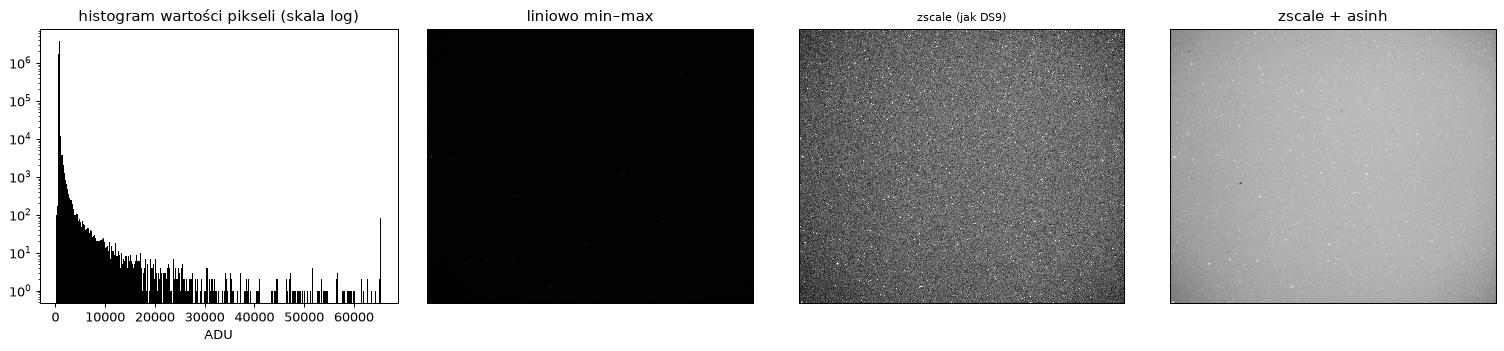

In [5]:
img = data.astype(np.float32)
print(f"min={img.min():.0f}  mediana={np.median(img):.0f}  max={img.max():.0f}  std={img.std():.1f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].hist(img.ravel(), bins=300, log=True, color="k")
axes[0].set_title("histogram wartości pikseli (skala log)"); axes[0].set_xlabel("ADU")

axes[1].imshow(img, cmap="gray"); axes[1].set_title("liniowo min–max")
zscale_show(axes[2], img, "zscale (jak DS9)")
axes[3].imshow(img, cmap="gray", norm=ImageNormalize(img, interval=ZScaleInterval(), stretch=AsinhStretch()))
axes[3].set_title("zscale + asinh")
for a in axes[1:]:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Nagłówek WCS — skąd wiemy, gdzie na niebie jest piksel?

**WCS** (*World Coordinate System*) to zestaw kluczy w nagłówku, które opisują **przekształcenie piksel → współrzędne na niebie** (rektascensja RA, deklinacja Dec). Plik z WCS to plik, który „wie”, na co patrzy.

Jak się go dostaje? Program **plate solving** (u nas Astrometry.net, folder `plate-solve-container/`) rozpoznaje układy gwiazd na zdjęciu, dopasowuje je do katalogu i dopisuje WCS do nagłówka.

| Klucz | Znaczenie | Nasz plik |
|---|---|---|
| `CTYPE1/2` | typ projekcji. `RA---TAN` = projekcja gnomoniczna (sfera → płaszczyzna), `-SIP` = plus poprawka na zniekształcenia optyki | `RA---TAN-SIP` |
| `CRPIX1/2` | **piksel referencyjny** (indeksowany od 1!) | |
| `CRVAL1/2` | RA i Dec [°] w pikselu referencyjnym | |
| `CD1_1 … CD2_2` | macierz 2×2: o ile stopni zmienia się RA/Dec przy kroku o 1 piksel. Zawiera **skalę** (″/px) i **obrót** obrazu | |
| `A_p_q`, `B_p_q` (SIP) | wielomianowe poprawki zniekształceń (piksel → niebo) | |
| `AP_p_q`, `BP_p_q` | odwrotne poprawki (niebo → piksel) | |

W uproszczeniu (bez SIP):

$$\begin{pmatrix}\xi\\ \eta\end{pmatrix} = \mathbf{CD}\begin{pmatrix}x - \mathrm{CRPIX1}\\ y - \mathrm{CRPIX2}\end{pmatrix}$$

a potem $(\xi, \eta)$ na płaszczyźnie stycznej rzutuje się z powrotem na sferę wokół punktu `CRVAL`.

In [6]:
w = WCS(header)
print(w)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 270.9726974 39.5533124535
CRPIX : 1929.85449219 1259.95131429
CD1_1 CD1_2  : -0.000921520667682 0.00079738804297
CD2_1 CD2_2  : -0.000797785810809 -0.000920372749553
NAXIS : 2560  2160


In [7]:
# Piksel -> niebo (astropy liczy piksele od 0!)
ny, nx = data.shape
corners = {"lewy dolny": (0, 0), "środek": (nx / 2, ny / 2), "prawy górny": (nx - 1, ny - 1)}
for name, (x, y) in corners.items():
    sky = w.pixel_to_world(x, y)
    print(f"{name:12s} piksel ({x:7.1f}, {y:7.1f})  ->  RA={sky.ra.deg:9.4f}°  Dec={sky.dec.deg:8.4f}°   ({sky.to_string('hmsdms', precision=0)})")

# Niebo -> piksel (w drugą stronę)
center = w.pixel_to_world(nx / 2, ny / 2)
print("\nOdwrotnie:", w.world_to_pixel(center))

# Skala i obrót z macierzy CD
cd = w.wcs.cd
scale = np.sqrt(np.abs(np.linalg.det(cd))) * 3600
rotation = np.degrees(np.arctan2(cd[1, 0], cd[1, 1]))
print(f"\nSkala: {scale:.2f} ″/piksel  |  obrót obrazu względem północy: {rotation:.1f}°")
print(f"Pole widzenia: {nx * scale / 3600:.2f}° × {ny * scale / 3600:.2f}°")

lewy dolny   piksel (    0.0,     0.0)  ->  RA= 272.0169°  Dec= 42.2474°   (18h08m04s +42d14m50s)
środek       piksel ( 1280.0,  1080.0)  ->  RA= 271.5691°  Dec= 40.2343°   (18h06m17s +40d14m04s)
prawy górny  piksel ( 2559.0,  2159.0)  ->  RA= 271.1470°  Dec= 38.2231°   (18h04m35s +38d13m23s)

Odwrotnie: (array(1280.), array(1080.))

Skala: 4.39 ″/piksel  |  obrót obrazu względem północy: -139.1°
Pole widzenia: 3.12° × 2.63°


Dzięki WCS możemy narysować obraz z siatką współrzędnych niebieskich. Widać, że obraz jest **obrócony** — północ nie jest „do góry”:

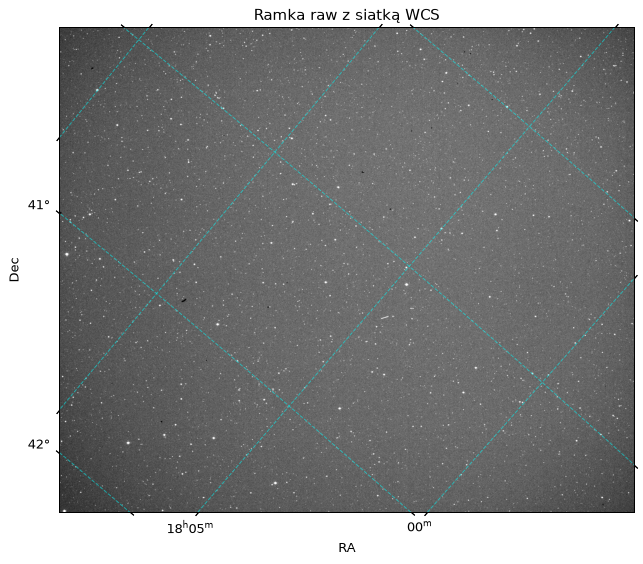

In [8]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection=w)
finite = img[np.isfinite(img)]
vmin, vmax = ZScaleInterval().get_limits(finite)
ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
ax.coords.grid(color="cyan", alpha=0.5, linestyle="--")
ax.coords[0].set_axislabel("RA"); ax.coords[1].set_axislabel("Dec")
ax.set_title("Ramka raw z siatką WCS")
plt.show()

### Po co nam WCS w wykrywaniu śladów?
1. **Wspólna siatka pikseli.** Teleskop nigdy nie trafia idealnie w to samo miejsce — kolejne ramki są minimalnie przesunięte/obrócone. Preprocessing **reprojektuje** wszystkie ramki na WCS jednej ramki referencyjnej, żeby gwiazda leżała w tym samym pikselu w każdej ramce. Bez tego nie da się ani odjąć gwiazd, ani stackować.
2. **Wynik w jednostkach fizycznych.** Pozycja i prędkość śladu w pikselach nic nie mówią orbitologowi — potrzebuje RA/Dec i ″/s. Np. ślad o prędkości 100 px/s to:

In [9]:
print(f"100 px/s × {scale:.2f} ″/px = {100 * scale:.0f} ″/s = {100 * scale / 60:.1f} ′/s")

100 px/s × 4.39 ″/px = 439 ″/s = 7.3 ′/s


## 3. DS9 — przeglądarka plików FITS

[SAOImage DS9](https://sites.google.com/cfa.harvard.edu/saoimageds9) to standardowe narzędzie do oglądania FITS-ów. W notebooku robimy wycinki, ale **do oglądania całych ramek i „mrugania” między nimi DS9 jest dużo wygodniejsze**.

### Instalacja
```bash
# Ubuntu / Debian
sudo apt install saods9
# macOS
brew install --cask saoimage-ds9
# Windows / inne: binarka ze strony DS9
```

### Najważniejsze rzeczy w GUI
- **Scale → zscale** — bez tego zobaczysz czarny obraz (patrz sekcja 1).
- **Color → grey / heat**; prawy przycisk myszy + przeciąganie = zmiana kontrastu.
- Na dole: współrzędne kursora w pikselach **i** w WCS (RA/Dec) — DS9 sam czyta nagłówek WCS.
- **File → Header** — podgląd nagłówka.
- **Frame → New Frame** + **Frame → Blink** — mruganie między ramkami. Najlepszy sposób, żeby **zobaczyć ruch** satelity na tle nieruchomych gwiazd.
- **Frame → Lock → Frame → WCS** — przybliżenie/przesunięcie w jednej ramce działa we wszystkich.
- **Region** — zaznaczanie obiektów (linie, okręgi), zapis/odczyt plików `.reg`.

### Komendy z terminala (uruchamiaj z folderu `wprowadzenie-fits/`)
```bash
# 1 ramka, zscale, szara paleta
ds9 ramki_fits/slady_syntetyczne/raw/frame_000.fits -zscale -cmap grey

# raw obok preprocessed (przed/po usunięciu gwiazd), zsynchronizowane po WCS
ds9 -tile column ramki_fits/slady_syntetyczne/raw/frame_000.fits ramki_fits/slady_syntetyczne/preprocessed/frame_000.fits \
    -zscale -cmap grey -lock frame wcs -lock scalelimits yes

# wszystkie ramki raw w trybie mrugania (widać ruch śladów)
ds9 ramki_fits/slady_syntetyczne/raw/*.fits -zscale -cmap grey -lock frame wcs -blink interval 0.5 -blink

# ramka + zaznaczone prawdziwe ślady (plik regionów generujemy niżej)
ds9 ramki_fits/slady_syntetyczne/raw/frame_000.fits -zscale -cmap grey -regions load wyniki/slady_syntetyczne_frame0.reg
```

Jak ustawić otwieranie plików `.fits` dwuklikiem w DS9: zob. README.

### Pliki regionów `.reg`
Plik regionów to zwykły tekst. Wygenerujmy pliki z prawdziwymi pozycjami śladów, żeby w DS9 było wiadomo, gdzie patrzeć. **Uwaga:** DS9 liczy piksele od 1, a nasze konfigi od 0 — dlatego `+1`.

In [10]:
def streak_center(tr, frame_idx, anchor):
    # Środek śladu w danej ramce (piksele od 0). Oba symulatory zapisują (x, y) inaczej:
    # anchor='middle' -> (x, y) to środek śladu (zestaw syntetyczny),
    # anchor='corner' -> (x, y) to lewy dolny róg prostokątnego "stempla" z obróconym
    #                    śladem (zestaw hybrydowy, patrz simulator/hybrid/streak.py).
    x, y = tr["xy"][frame_idx]
    if anchor == "middle":
        return x, y
    sigma = tr["fwhm"] / (2 * np.sqrt(2 * np.log(2)))
    n = max(3, math.ceil(sigma * 10))           # szerokość stempla przed obrotem
    w0, h0 = math.ceil(tr["v"] * tr["exp"]) + n, n
    a = np.deg2rad(tr["ang"])
    W = int(abs(w0 * np.cos(a)) + abs(h0 * np.sin(a)) + 0.5)
    H = int(abs(w0 * np.sin(a)) + abs(h0 * np.cos(a)) + 0.5)
    return x + (W - 1) / 2, y + (H - 1) / 2


def streak_segment(tr, frame_idx, anchor):
    # Początek i koniec śladu w danej ramce (piksele od 0).
    cx, cy = streak_center(tr, frame_idx, anchor)
    dx, dy = direction(tr["ang"])
    L = tr["v"] * tr["exp"]  # długość śladu = prędkość × czas ekspozycji
    return (cx - dx * L / 2, cy - dy * L / 2), (cx + dx * L / 2, cy + dy * L / 2)


def write_ds9_regions(dataset, anchor, frame_idx, path):
    lines = ["# Region file format: DS9 version 4.1",
             'global color=lime width=2 font="helvetica 12 bold"',
             "image"]
    for tr in load_truth(dataset):
        (x0, y0), (x1, y1) = streak_segment(tr, frame_idx, anchor)
        lines.append(f"line({x0 + 1:.1f},{y0 + 1:.1f},{x1 + 1:.1f},{y1 + 1:.1f}) # line=0 1")
        lines.append(f"circle({x0 + 1:.1f},{y0 + 1:.1f},25) # color=yellow "
                     f"text={{{tr['name']} SNR={tr['snr']:.2f} v={tr['v']:.0f}px/s}}")
    Path(path).write_text("\n".join(lines) + "\n")
    return path


for ds, anchor in [(HYB, "corner"), (SYN, "middle")]:
    for i in [0]:
        p = write_ds9_regions(ds, anchor, i, OUT / f"{ds.name}_frame{i}.reg")
        print("zapisano", p)
print()
print((OUT / "slady_syntetyczne_frame0.reg").read_text())

zapisano wyniki/slady_hybrydowe_frame0.reg
zapisano wyniki/slady_syntetyczne_frame0.reg

# Region file format: DS9 version 4.1
global color=lime width=2 font="helvetica 12 bold"
image
line(1327.5,657.6,1324.5,668.4) # line=0 1
circle(1327.5,657.6,25) # color=yellow text={T3 SNR=2.81 v=11px/s}
line(1304.2,1508.5,1333.8,1509.5) # line=0 1
circle(1304.2,1508.5,25) # color=yellow text={T4 SNR=2.92 v=30px/s}
line(745.0,1082.4,755.0,1097.6) # line=0 1
circle(745.0,1082.4,25) # color=yellow text={T5 SNR=3.98 v=18px/s}
line(832.5,892.9,855.5,889.1) # line=0 1
circle(832.5,892.9,25) # color=yellow text={T0 SNR=6.08 v=23px/s}
line(609.1,1414.4,616.9,1395.6) # line=0 1
circle(609.1,1414.4,25) # color=yellow text={T1 SNR=6.75 v=20px/s}
line(1333.9,897.1,1340.1,896.9) # line=0 1
circle(1333.9,897.1,25) # color=yellow text={T2 SNR=7.33 v=6px/s}



DS9 można też uruchomić prosto z notebooka (działa tylko lokalnie, gdy `ds9` jest w `PATH`). Zmień `OPEN_DS9 = True`, żeby spróbować:

In [11]:
OPEN_DS9 = False

def open_in_ds9(*fits_paths, regions=None, extra=()):
    if shutil.which("ds9") is None:
        print("Nie znaleziono ds9 w PATH — zainstaluj (patrz wyżej).")
        return
    cmd = ["ds9", *map(str, fits_paths), "-zscale", "-cmap", "grey", "-lock", "frame", "wcs", *extra]
    if regions:
        cmd += ["-regions", "load", "all", str(regions)]
    print(" ".join(cmd))
    subprocess.Popen(cmd)  # nie blokuje notebooka

if OPEN_DS9:
    open_in_ds9(SYN / "raw" / "frame_000.fits", regions=OUT / "slady_syntetyczne_frame0.reg")

## 4. Galeria przypadków: od „nic nie widać” do „widać gołym okiem”

Wczytujemy wszystkie ramki obu zestawów (raw i preprocessed). To ~1 GB w RAM-ie, chwilę potrwa.

In [12]:
t0 = time.perf_counter()
hyb_files, hyb_raw, hyb_t = load_frames(HYB / "raw")
_, hyb_pre, _ = load_frames(HYB / "preprocessed", zero_is_nan=True)
syn_files, syn_raw, syn_t = load_frames(SYN / "raw")
_, syn_pre, _ = load_frames(SYN / "preprocessed", zero_is_nan=True)
empty = fits.getdata(EMPTY).astype(np.float32)

hyb_truth, syn_truth = load_truth(HYB), load_truth(SYN)
print(f"wczytano w {time.perf_counter() - t0:.1f} s")
print("odstępy między ramkami [s] (hybrydowe):", np.round(np.diff(hyb_t), 3))

for label, truth in [("HYBRYDOWE", hyb_truth), ("SYNTETYCZNE", syn_truth)]:
    print(f"\n{label}")
    for tr in truth:
        print(f"  {tr['name']}: SNR={tr['snr']:6.3f}  v={tr['v']:7.2f} px/s  kąt={tr['ang']:6.1f}°  start(ramka 0)={tr['xy'][0]}")

wczytano w 0.9 s
odstępy między ramkami [s] (hybrydowe): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

HYBRYDOWE
  T5: SNR= 0.070  v=  61.20 px/s  kąt= 163.5°  start(ramka 0)=(1894, 915)
  T6: SNR= 0.120  v= 106.53 px/s  kąt= 125.9°  start(ramka 0)=(1420, 909)
  T0: SNR= 0.187  v= 174.49 px/s  kąt=  59.7°  start(ramka 0)=(1516, 264)
  T1: SNR= 0.391  v= 110.00 px/s  kąt= 168.8°  start(ramka 0)=(2200, 907)
  T2: SNR= 0.592  v=  86.20 px/s  kąt=  36.4°  start(ramka 0)=(1444, 1237)
  T3: SNR= 0.840  v= 111.97 px/s  kąt=   7.5°  start(ramka 0)=(935, 315)
  T4: SNR= 0.955  v= 126.49 px/s  kąt= 105.1°  start(ramka 0)=(1387, 66)

SYNTETYCZNE
  T3: SNR= 2.808  v=  11.31 px/s  kąt= 105.8°  start(ramka 0)=(1325, 662)
  T4: SNR= 2.918  v=  29.55 px/s  kąt=   2.1°  start(ramka 0)=(1318, 1508)
  T5: SNR= 3.975  v=  18.25 px/s  kąt=  56.5°  start(ramka 0)=(749, 1089)
  T0: SNR= 6.083  v=  23.30 px/s  kąt= 350.8°  start(ramka 0)=(843, 890)
  T1: SNR= 6.746  v=  20.34 px/s  kąt= 292.8°  start(ramka 0)=(612, 1404)


Każdy panel to wycinek **jednej ramki raw** wokół miejsca, gdzie wiemy (z configu), że jest ślad. Zielona przerywana linia (prawa kolumna każdej pary) pokazuje, gdzie ślad *powinien* być. Spróbuj najpierw znaleźć go **bez** podpowiedzi.

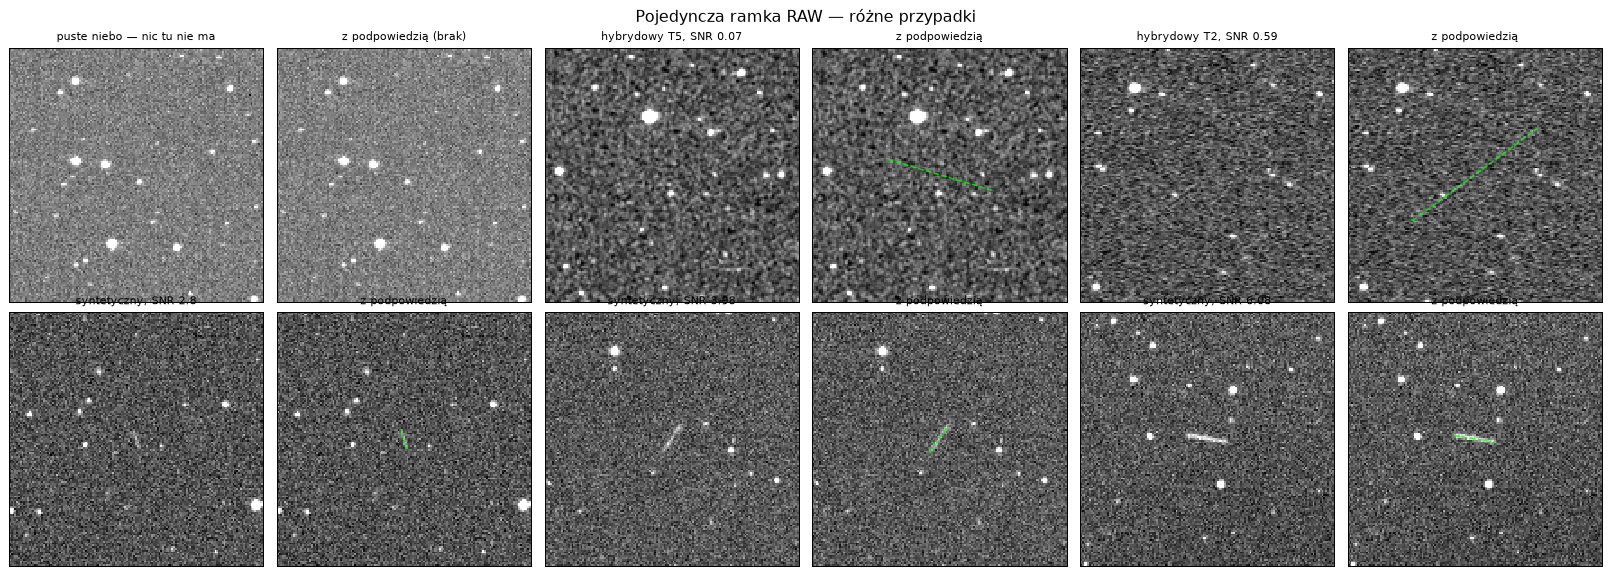

In [13]:
def show_case(ax_pair, frame, tr, anchor, half, title):
    (x0, y0), (x1, y1) = streak_segment(tr, 0, anchor)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    c = cutout(frame, cx, cy, half)
    for k, ax in enumerate(ax_pair):
        zscale_show(ax, c, title if k == 0 else "z podpowiedzią")
    ax_pair[1].plot([x0 - cx + half, x1 - cx + half], [y0 - cy + half, y1 - cy + half],
                    "--", color="lime", lw=1.2, alpha=0.8)


cases = [
    ("puste niebo — nic tu nie ma", None, None, None),
    ("hybrydowy T5, SNR 0.07", hyb_raw[0], hyb_truth[0], "corner"),
    ("hybrydowy T2, SNR 0.59", hyb_raw[0], [t for t in hyb_truth if t["name"] == "T2"][0], "corner"),
    ("syntetyczny, SNR 2.8", syn_raw[0], syn_truth[0], "middle"),
    ("syntetyczny, SNR 3.98", syn_raw[0], syn_truth[2], "middle"),
    ("syntetyczny, SNR 6.08", syn_raw[0], syn_truth[3], "middle"),
]

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for i, (title, frame, tr, anchor) in enumerate(cases):
    pair = axes[i // 3, (i % 3) * 2: (i % 3) * 2 + 2]
    if frame is None:
        c = cutout(empty, 1300, 1100, 70)
        zscale_show(pair[0], c, title); zscale_show(pair[1], c, "z podpowiedzią (brak)")
    else:
        show_case(pair, frame, tr, anchor, 70, title)
plt.suptitle("Pojedyncza ramka RAW — różne przypadki", fontsize=13)
plt.tight_layout(); plt.show()

**Wnioski:**
- **Puste niebo** — gwiazdy, szum, ewentualnie gorące piksele czy promienie kosmiczne. Detektor musi umieć powiedzieć „nic tu nie ma” — fałszywe alarmy są równie złe jak przeoczenia.
- **SNR ≪ 1** (hybrydowe T5, T2) — ślad jest fizycznie w danych, ale w pojedynczej ramce **nie da się go zobaczyć**: każdy jego piksel jest słabszy niż szum.
- **SNR ~ 3** — przy podpowiedzi da się dostrzec, bez niej łatwo pomylić z szumem albo przeoczyć obok gwiazdy.
- **SNR ≳ 5** — widać od razu.

Pełną ramkę z zaznaczonymi śladami najlepiej obejrzeć w DS9 (`wyniki/*.reg`). Dla porządku — cała ramka syntetyczna z zaznaczonymi miejscami:

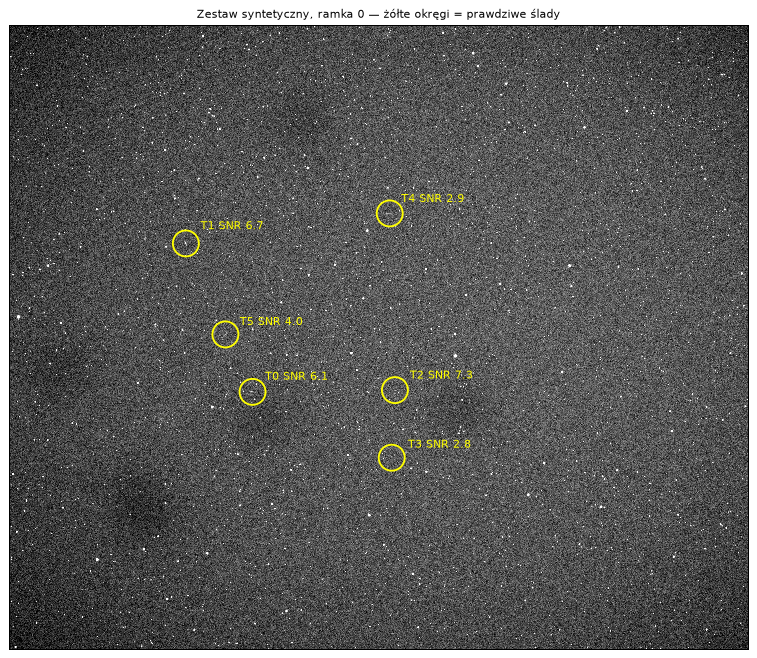

In [14]:
fig, ax = plt.subplots(figsize=(11, 9))
zscale_show(ax, syn_raw[0], "Zestaw syntetyczny, ramka 0 — żółte okręgi = prawdziwe ślady")
for tr in syn_truth:
    (x0, y0), (x1, y1) = streak_segment(tr, 0, "middle")
    ax.add_patch(plt.Circle(((x0 + x1) / 2, (y0 + y1) / 2), 45, fill=False, color="yellow", lw=1.5))
    ax.text(x0 + 55, y0 + 40, f"{tr['name']} SNR {tr['snr']:.1f}", color="yellow", fontsize=9)
plt.show()

## 5. Usuwanie gwiazd — przed i po

Gwiazdy to dla nas **szum strukturalny**: są jasne, jest ich tysiące, a ślad przechodzący obok gwiazdy łatwo zgubić (albo wziąć kawałek gwiazdy za ślad). Ponieważ gwiazdy **stoją w miejscu**, a satelita **się rusza**, możemy je usunąć:

1. **Ujednolicenie WCS** — reprojekcja wszystkich ramek na jedną siatkę (sekcja 2).
2. **Mediana po czasie** — dla każdego piksela bierzemy medianę z N ramek. Gwiazda jest w tym pikselu zawsze → zostaje w medianie. Satelita jest w danym pikselu tylko w 1 ramce → mediana go „nie widzi”. Wynik = **mapa statycznego nieba**.
3. **Odejmowanie**: `ramka − mediana` → zostaje szum + wszystko, co się ruszało.
4. **Maskowanie resztek** — jasne gwiazdy nie odejmują się idealnie (seeing, nasycenie), więc ich okolice są maskowane (w plikach `preprocessed/` mają wartość `0`; u nas pokazane na niebiesko jako NaN).

Tak działa `synthetic-tracking/synthetic_tracking/preprocessing/static_star_field.py`. Porównajmy:

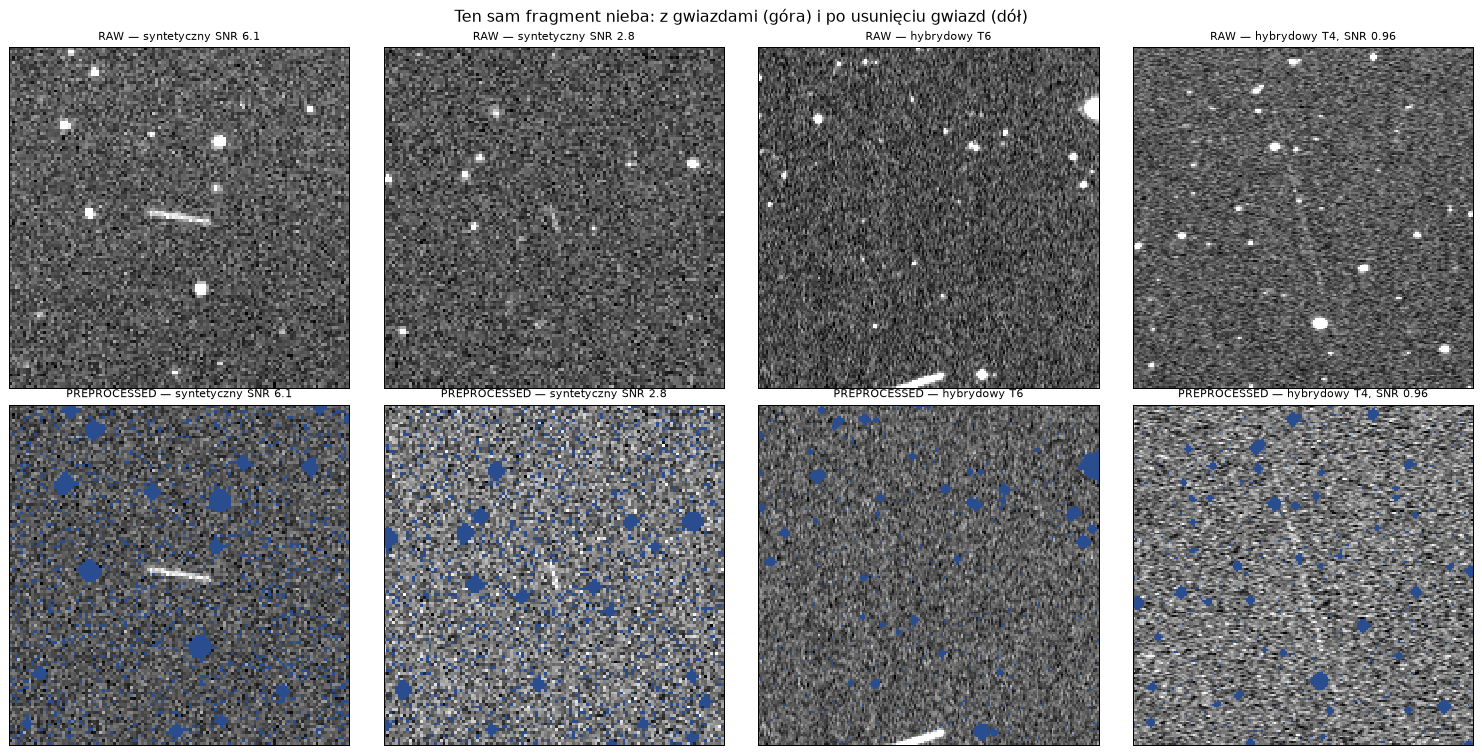

In [15]:
def compare_raw_pre(raw, pre, tr, anchor, half, label):
    (x0, y0), (x1, y1) = streak_segment(tr, 0, anchor)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    return cutout(raw, cx, cy, half), cutout(pre, cx, cy, half), label


panels = [
    compare_raw_pre(syn_raw[0], syn_pre[0], syn_truth[3], "middle", 60, "syntetyczny SNR 6.1"),
    compare_raw_pre(syn_raw[0], syn_pre[0], syn_truth[0], "middle", 60, "syntetyczny SNR 2.8"),
    compare_raw_pre(hyb_raw[0], hyb_pre[0], [t for t in hyb_truth if t["name"] == "T6"][0], "corner", 90, "hybrydowy T6"),
    compare_raw_pre(hyb_raw[0], hyb_pre[0], [t for t in hyb_truth if t["name"] == "T4"][0], "corner", 90, "hybrydowy T4, SNR 0.96"),
]
fig, axes = plt.subplots(2, len(panels), figsize=(4.2 * len(panels), 8.5))
for j, (r, p, label) in enumerate(panels):
    zscale_show(axes[0, j], r, f"RAW — {label}")
    zscale_show(axes[1, j], p, f"PREPROCESSED — {label}")
plt.suptitle("Ten sam fragment nieba: z gwiazdami (góra) i po usunięciu gwiazd (dół)", fontsize=13)
plt.tight_layout(); plt.show()

Zróbmy to samo „ręcznie” na zestawie syntetycznym, żeby było jasne, że to nie magia — wystarczy mediana i odejmowanie (ramki tego zestawu mają już wspólny WCS, więc pomijamy reprojekcję):

mediana z 13 ramek: 1.4 s


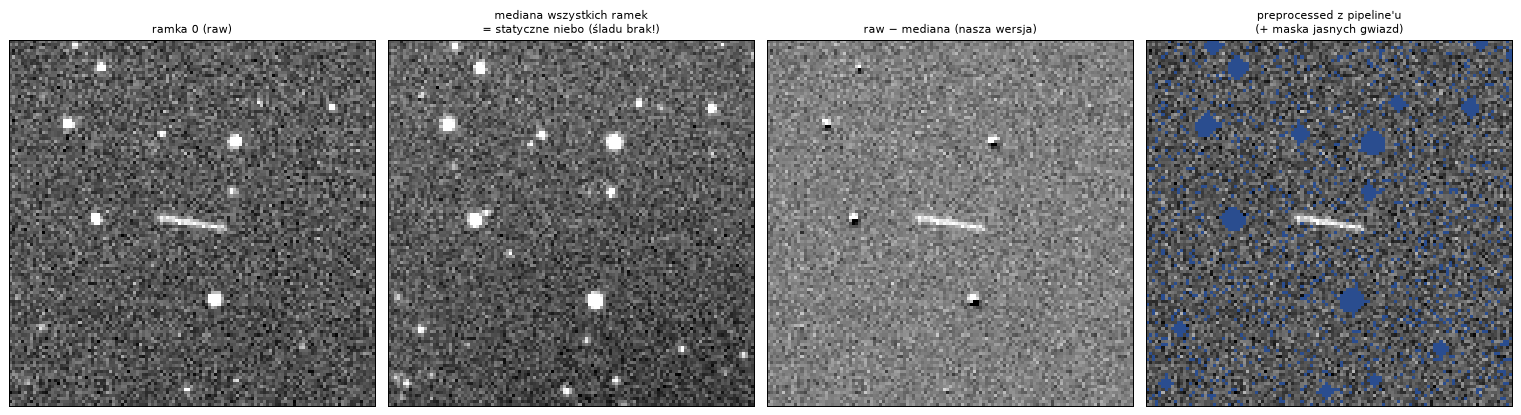

In [16]:
t0 = time.perf_counter()
static_sky = np.median(np.stack(syn_raw), axis=0)  # mapa statycznego nieba
residual = syn_raw[0] - static_sky                  # ramka 0 minus gwiazdy
print(f"mediana z {len(syn_raw)} ramek: {time.perf_counter() - t0:.1f} s")

tr = syn_truth[3]
(x0, y0), (x1, y1) = streak_segment(tr, 0, "middle")
cx, cy, h = (x0 + x1) / 2, (y0 + y1) / 2, 60
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
zscale_show(axes[0], cutout(syn_raw[0], cx, cy, h), "ramka 0 (raw)")
zscale_show(axes[1], cutout(static_sky, cx, cy, h), "mediana wszystkich ramek\n= statyczne niebo (śladu brak!)")
zscale_show(axes[2], cutout(residual, cx, cy, h), "raw − mediana (nasza wersja)")
zscale_show(axes[3], cutout(syn_pre[0], cx, cy, h), "preprocessed z pipeline'u\n(+ maska jasnych gwiazd)")
plt.tight_layout(); plt.show()

**Na co uważać przy usuwaniu gwiazd:**
- **Wolne obiekty.** Jeśli obiekt przesuwa się o mniej niż swoją szerokość w trakcie całej sekwencji, mediana uzna go za gwiazdę i **wytnie**. Zestaw syntetyczny ma ślad o prędkości ~6 px/s — sprawdź w DS9, jak wygląda po preprocessingu.
- **Maska zjada piksele.** Ślad przechodzący przez zamaskowaną gwiazdę traci fragment.
- **Mało ramek → zaszumiona mediana**, którą odejmujemy od każdej ramki (dokładamy szum).
- Zmiany warunków (chmury, księżyc, zmiana tła) psują założenie, że niebo jest statyczne.

## 6. Stackowanie (shift-and-stack, *synthetic tracking*)

### Idea
Szum w każdej ramce jest losowy i niezależny, a sygnał (ślad) — ten sam. Jeśli **zsumujemy / uśrednimy N ramek tak, żeby ślad nałożył się sam na siebie**, to:
- sygnał rośnie jak **N**,
- szum rośnie jak **√N**,
- więc **SNR rośnie jak √N**. Dla 11 ramek to ~3.3×, dla 100 ramek — 10×.

### Problem: satelita się rusza
Zwykłe uśrednienie ramek (tak jak w astrofotografii) **nakłada gwiazdy**, ale satelitę **rozmazuje** — w każdej ramce jest gdzie indziej. Dlatego robimy **shift-and-stack**: zakładamy prędkość `v` i kąt `θ`, każdą ramkę przesuwamy o `−v·t·(cos θ, sin θ)` (t = czas od pierwszej ramki) i dopiero wtedy uśredniamy. Jeśli założenie jest trafne, ślad z każdej ramki ląduje w tym samym miejscu.

Wtedy z kolei **rozmazują się gwiazdy** (to one się „ruszają” względem przesuwanych ramek): każda gwiazda pojawia się w stacku N razy, za każdym razem z jasnością 1/N, rozsiana wzdłuż kierunku ruchu. Jasne gwiazdy nadal są dobrze widoczne i mogą udawać ślady — kolejny powód, żeby je wcześniej usunąć.

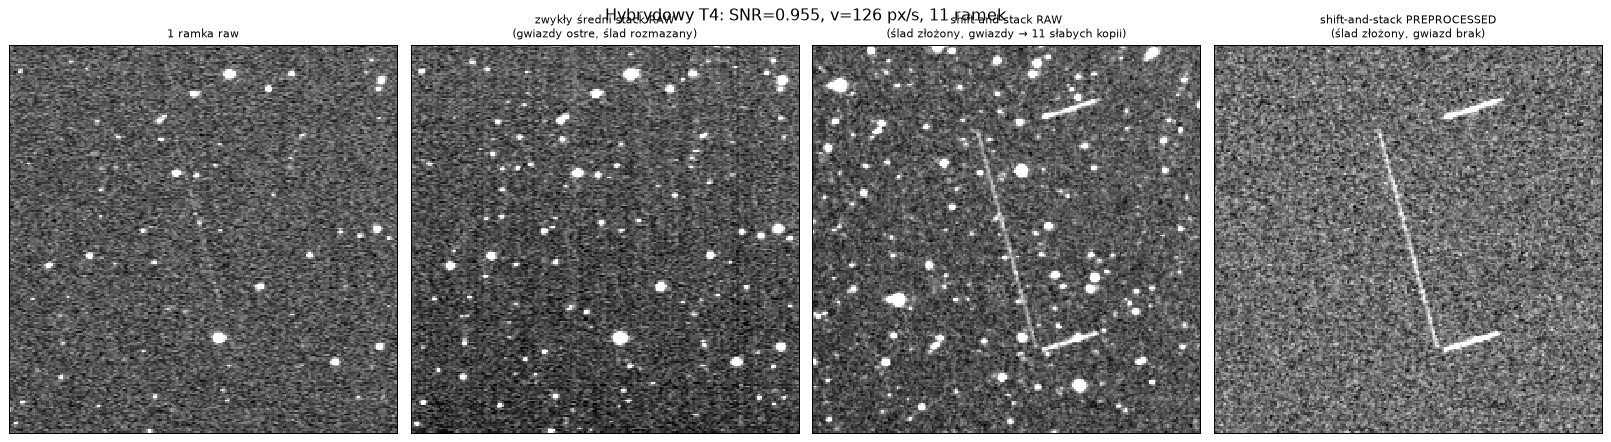

In [17]:
def shift_and_stack(frames, t, tr, anchor, half, v=None, ang=None, reducer=np.nanmean):
    # Shift-and-stack w wycinku wokół śladu z ramki 0, dla hipotezy (v, ang).
    # Domyślnie hipoteza = prawda z configu. Zamiast przesuwać całe ramki,
    # dla każdej ramki wycinamy (subpikselowo) okno w miejscu, gdzie obiekt
    # powinien być w chwili t — to matematycznie to samo, a dużo szybsze.
    v = tr["v"] if v is None else v
    ang = tr["ang"] if ang is None else ang
    dx, dy = direction(ang)
    (x0, y0), (x1, y1) = streak_segment(tr, 0, anchor)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    stack = [cutout(f, cx + v * dx * ti, cy + v * dy * ti, half) for f, ti in zip(frames, t)]
    return reducer(np.stack(stack), axis=0)


def naive_stack(frames, tr, anchor, half):
    (x0, y0), (x1, y1) = streak_segment(tr, 0, anchor)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    return np.nanmean(np.stack([cutout(f, cx, cy, half) for f in frames]), axis=0)


tr = [t for t in hyb_truth if t["name"] == "T4"][0]  # SNR 0.96, v=126 px/s
H = 110
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
zscale_show(axes[0], cutout(hyb_raw[0], *np.mean(streak_segment(tr, 0, "corner"), axis=0), H), "1 ramka raw")
zscale_show(axes[1], naive_stack(hyb_raw, tr, "corner", H), "zwykły średni stack RAW\n(gwiazdy ostre, ślad rozmazany)")
zscale_show(axes[2], shift_and_stack(hyb_raw, hyb_t, tr, "corner", H), "shift-and-stack RAW\n(ślad złożony, gwiazdy → 11 słabych kopii)")
zscale_show(axes[3], shift_and_stack(hyb_pre, hyb_t, tr, "corner", H), "shift-and-stack PREPROCESSED\n(ślad złożony, gwiazd brak)")
plt.suptitle(f"Hybrydowy {tr['name']}: SNR={tr['snr']}, v={tr['v']:.0f} px/s, {len(hyb_raw)} ramek", fontsize=13)
plt.tight_layout(); plt.show()

### Ślad przed i po stackowaniu
Górny rząd: **pojedyncza** ramka preprocessed. Dolny: shift-and-stack wszystkich 11 ramek z **prawdziwą** prędkością i kątem.

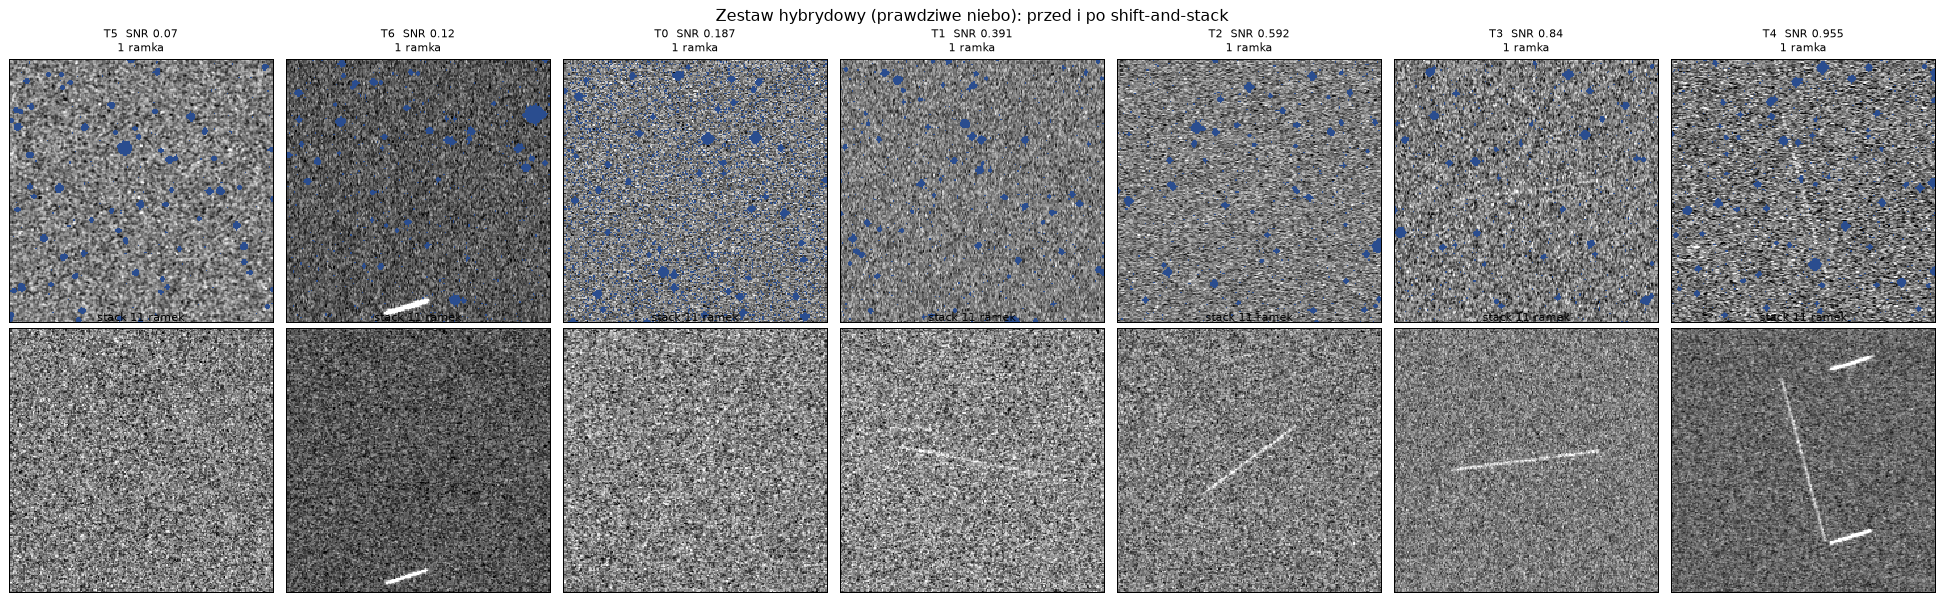

In [18]:
H = 100
fig, axes = plt.subplots(2, len(hyb_truth), figsize=(3.1 * len(hyb_truth), 6.8))
for j, tr in enumerate(hyb_truth):
    center = np.mean(streak_segment(tr, 0, "corner"), axis=0)
    zscale_show(axes[0, j], cutout(hyb_pre[0], *center, H), f"{tr['name']}  SNR {tr['snr']}\n1 ramka")
    zscale_show(axes[1, j], shift_and_stack(hyb_pre, hyb_t, tr, "corner", H), f"stack {len(hyb_pre)} ramek")
plt.suptitle("Zestaw hybrydowy (prawdziwe niebo): przed i po shift-and-stack", fontsize=13)
plt.tight_layout(); plt.show()

- **T2, T3, T4** (SNR 0.6–0.96): w pojedynczej ramce praktycznie niewidoczne, po stacku wyraźne.
- **T0, T1** (SNR 0.2–0.4): po stacku ledwo widoczne. 11 ramek to za mało, przydałoby się kilkadziesiąt.
- **T5, T6** (SNR ≤ 0.12): nie da się ich wyciągnąć nawet stackiem. Jasna kreska w kadrze T6 to **nie** T6, tylko prawdziwy, jasny obiekt z oryginalnych ramek (nie był wstrzyknięty), który akurat przelatuje obok.

Ilościowo: zmierzmy SNR śladu jako (średnia jasność wzdłuż śladu − tło) / (szum tła / √liczba pikseli śladu) — w pojedynczej ramce i w stacku. Teoretycznie poprawa powinna wynosić √N.

In [19]:
def measure_snr(img, tr, half):
    # SNR śladu w wycinku o środku w środku śladu (wycinek z cutout / shift_and_stack).
    dx, dy = direction(tr["ang"])
    L = tr["v"] * tr["exp"]
    yy, xx = np.mgrid[-half:half + 1, -half:half + 1]
    along = xx * dx + yy * dy           # odległość wzdłuż śladu
    across = -xx * dy + yy * dx         # odległość w poprzek śladu
    on = (np.abs(along) < L / 2 - 1) & (np.abs(across) < 1.0)
    bg = (np.abs(across) > 6) & (np.abs(across) < 30) & (np.abs(along) < L / 2 + 10)
    on &= np.isfinite(img); bg &= np.isfinite(img)
    bg_level = np.median(img[bg])
    bg_sigma = 1.4826 * np.median(np.abs(img[bg] - bg_level))  # odporne std (MAD)
    signal = np.mean(img[on]) - bg_level
    return signal / (bg_sigma / np.sqrt(on.sum())), bg_sigma


N = len(hyb_pre)
print(f"Liczba ramek N={N}, oczekiwana poprawa √N = {np.sqrt(N):.2f}\n")
print(f"{'ślad':5s} {'SNR config':>10s} | {'szum 1 ramka':>12s} {'szum stack':>10s} {'spadek':>7s} | "
      f"{'SNR 1 ramka':>11s} {'SNR stack':>9s}")
for tr in hyb_truth:
    half = int(tr["v"] * tr["exp"] / 2) + 35
    center = streak_center(tr, 0, "corner")
    snr1, sig1 = measure_snr(cutout(hyb_pre[0], *center, half), tr, half)
    snrN, sigN = measure_snr(shift_and_stack(hyb_pre, hyb_t, tr, "corner", half), tr, half)
    print(f"{tr['name']:5s} {tr['snr']:10.3f} | {sig1:12.1f} {sigN:10.1f} {sig1 / sigN:6.2f}× | {snr1:11.1f} {snrN:9.1f}")

Liczba ramek N=11, oczekiwana poprawa √N = 3.32

ślad  SNR config | szum 1 ramka szum stack  spadek | SNR 1 ramka SNR stack
T5         0.070 |         17.5        7.9   2.20× |         0.6       2.7
T6         0.120 |         24.1        7.8   3.07× |         1.0       4.4


T0         0.187 |         32.4        8.0   4.07× |         4.8      12.9
T1         0.391 |         23.5        8.1   2.90× |         5.9      18.1
T2         0.592 |         25.5        8.1   3.13× |         7.5      26.4


T3         0.840 |         21.4        8.9   2.41× |        13.9      37.5
T4         0.955 |         22.5        7.7   2.92× |        15.2      47.2


> **Jak to czytać:** szum tła po stacku spada mniej więcej √N razy (to jest „cały zysk” ze stackowania), a sygnał śladu zostaje ten sam — więc SNR rośnie. Nasz SNR to SNR **całej linii** (uśredniamy dziesiątki–setki pikseli wzdłuż śladu), a nie pojedynczego piksela jak w configu, dlatego liczby są większe. Pomiar na jednej ramce jest bardzo zaszumiony (może wyjść nawet ujemny!) — w końcu cały problem polega na tym, że w jednej ramce śladu nie widać. Spadek szumu może odbiegać od √N: przy krawędziach i w maskach gwiazd część pikseli ma mniej niż N ramek (mniejszy zysk), a interpolacja przy subpikselowym przesuwaniu wygładza szum (pozornie większy zysk).

To samo dla zestawu syntetycznego (13 ramek):

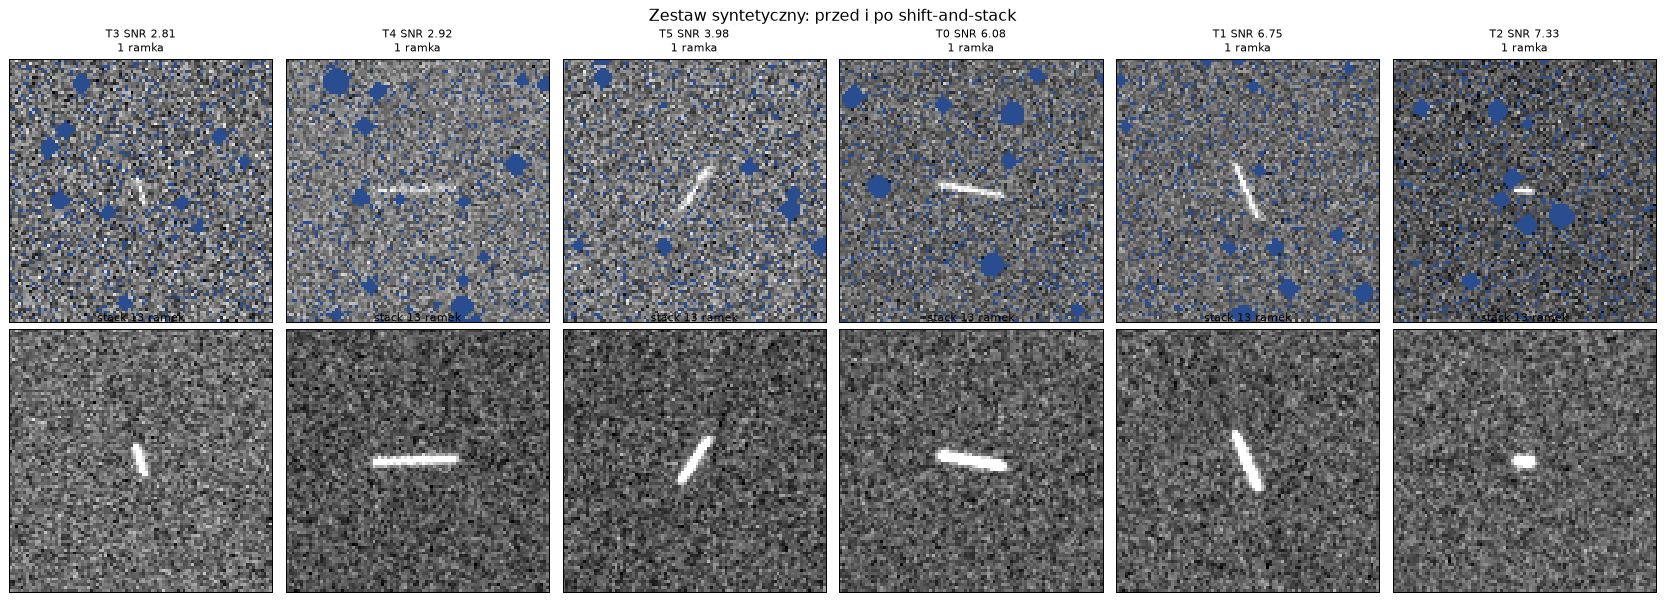

In [20]:
H = 45
fig, axes = plt.subplots(2, len(syn_truth), figsize=(3.1 * len(syn_truth), 6.8))
for j, tr in enumerate(syn_truth):
    center = np.mean(streak_segment(tr, 0, "middle"), axis=0)
    zscale_show(axes[0, j], cutout(syn_pre[0], *center, H), f"{tr['name']} SNR {tr['snr']:.2f}\n1 ramka")
    zscale_show(axes[1, j], shift_and_stack(syn_pre, syn_t, tr, "middle", H), f"stack {len(syn_pre)} ramek")
plt.suptitle("Zestaw syntetyczny: przed i po shift-and-stack", fontsize=13)
plt.tight_layout(); plt.show()

Zapiszmy jeden stack jako FITS (z nagłówkiem WCS ramki 0), żeby obejrzeć go w DS9 obok pojedynczej ramki:

In [21]:
tr = [t for t in hyb_truth if t["name"] == "T2"][0]
half = 300
stacked = shift_and_stack(hyb_pre, hyb_t, tr, "corner", half)
single = cutout(hyb_pre[0], *np.mean(streak_segment(tr, 0, "corner"), axis=0), half)

hdr = fits.Header()
hdr["COMMENT"] = f"shift-and-stack {len(hyb_pre)} ramek, slad {tr['name']}, v={tr['v']:.2f} px/s, ang={tr['ang']:.2f} deg"
fits.writeto(OUT / "stack_T2.fits", stacked.astype(np.float32), hdr, overwrite=True)
fits.writeto(OUT / "single_T2.fits", single.astype(np.float32), overwrite=True)
print("Otwórz w DS9:")
print(f"  ds9 -tile column {OUT}/single_T2.fits {OUT}/stack_T2.fits -zscale -cmap grey")

Otwórz w DS9:
  ds9 -tile column wyniki/single_T2.fits wyniki/stack_T2.fits -zscale -cmap grey


## 7. Problemy ze stackowaniem

Wszystko powyżej działało, bo **znaliśmy prawdziwą prędkość i kąt z configu**. W prawdziwej obserwacji ich nie znamy (szukamy nieznanych obiektów!). Co się dzieje, gdy hipoteza jest trochę błędna?

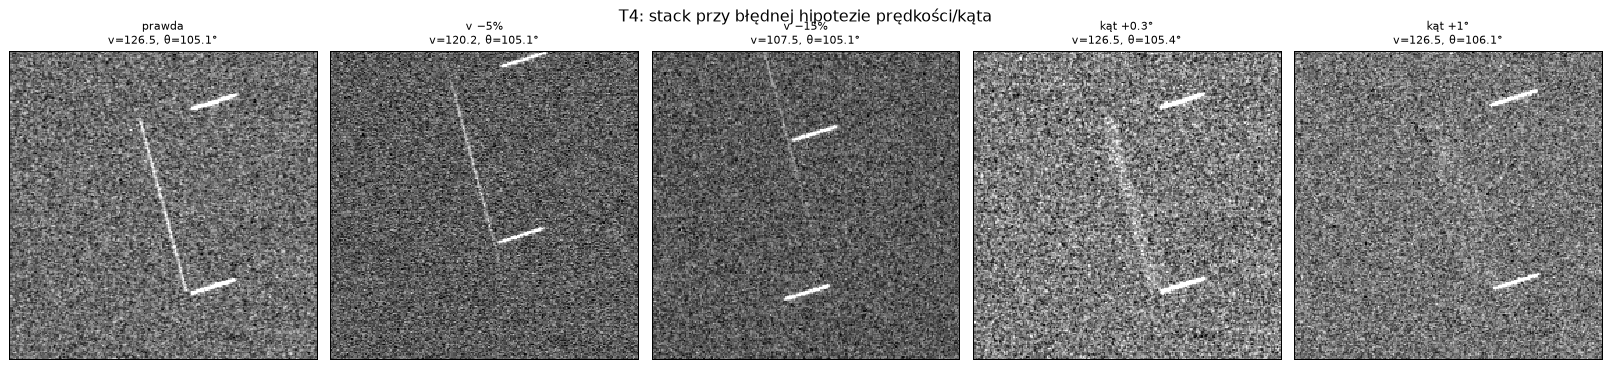

In [22]:
tr = [t for t in hyb_truth if t["name"] == "T4"][0]
H = 110
variants = [
    ("prawda", tr["v"], tr["ang"]),
    ("v −5%", tr["v"] * 0.95, tr["ang"]),
    ("v −15%", tr["v"] * 0.85, tr["ang"]),
    ("kąt +0.3°", tr["v"], tr["ang"] + 0.3),
    ("kąt +1°", tr["v"], tr["ang"] + 1),
]
fig, axes = plt.subplots(1, len(variants), figsize=(3.6 * len(variants), 4.2))
for ax, (label, v, a) in zip(axes, variants):
    zscale_show(ax, shift_and_stack(hyb_pre, hyb_t, tr, "corner", H, v=v, ang=a), f"{label}\nv={v:.1f}, θ={a:.1f}°")
plt.suptitle(f"{tr['name']}: stack przy błędnej hipotezie prędkości/kąta", fontsize=13)
plt.tight_layout(); plt.show()

(Dwa jasne, krótkie kreski w każdym panelu to **nie** T4 — to prawdziwy, jasny obiekt z oryginalnych ramek, który przecina ten fragment nieba w dwóch ramkach. Nawet uśredniony z wagą 1/11 jest jaśniejszy niż nasz słaby ślad. Tak wyglądają typowe „zakłócacze”.)

Ciekawa asymetria:
- **Błąd prędkości** (−5%, −15%) przesuwa kolejne kopie śladu **wzdłuż** niego samego — ślad się tylko wydłuża i trochę blednie. Przy długich śladach (tu 126 px na ramkę) to wybacza sporo.
- **Błąd kąta** przesuwa kopie **w poprzek** śladu. Po czasie $T$ przesunięcie wynosi $v \cdot \Delta\theta \cdot T$; dla $v=126$ px/s, $T=10$ s i $\Delta\theta=1°$ to **22 piksele**, czyli ~15× FWHM. Ślad znika całkowicie.

Warunek, żeby ślad się nie rozmył w poprzek:

$$v\cdot\Delta\theta\cdot T \lesssim \text{FWHM} \approx 1.5\ \text{px} \quad\Rightarrow\quad \Delta\theta \lesssim \frac{\text{FWHM}}{v\,T}$$

Dla szybkiego obiektu to **setne części stopnia**. Wzdłuż śladu tolerancja jest luźniejsza: $\Delta v \cdot T \lesssim$ ~połowa długości śladu ($v \cdot t_\text{exp}/2$), ale nie mniej niż FWHM.

Czyli **trzeba przeszukać całą siatkę hipotez** $(v, \theta)$: dla każdej zrobić pełny stack całej ramki i sprawdzić, czy coś „wyskoczyło”. Tak działa krok `survey` w `synthetic-tracking/synthetic_tracking/init_shift_and_stack/survey.py` (configi mają `v_granulation` i `ang_granulation`). Krok 1° wygląda niewinnie, a jak widać wyżej, dla szybkich obiektów jest za gruby.

### Ile to kosztuje?
Zmierzmy czas **jednego** stacku pełnych ramek (jedna hipoteza):

In [23]:
def full_frame_shift_and_stack(frames, t, v, ang):
    dx, dy = direction(ang)
    acc = np.zeros_like(frames[0])
    for f, ti in zip(frames, t):
        acc += subpixel_shift(np.nan_to_num(f), (-v * dy * ti, -v * dx * ti), order=1)
    return acc / len(frames)

t0 = time.perf_counter()
_ = full_frame_shift_and_stack(hyb_pre, hyb_t, 100.0, 45.0)
t_one = time.perf_counter() - t0
print(f"1 hipoteza, {len(hyb_pre)} ramek {hyb_pre[0].shape[1]}×{hyb_pre[0].shape[0]}: {t_one:.2f} s (CPU, 1 wątek)")

1 hipoteza, 11 ramek 2560×2160: 1.13 s (CPU, 1 wątek)


In [24]:
FWHM = 1.5        # px
EXP = 1.0         # czas ekspozycji jednej ramki [s]
CADENCE = 1.0     # odstęp między ramkami [s]


def count_hypotheses(v_max, n_frames, v_min=0.5):
    # Liczba hipotez (v, θ) potrzebnych, żeby żaden ślad o v_min..v_max nie "przeleciał" między oczkami siatki.
    T = (n_frames - 1) * CADENCE
    total, v = 0, v_min
    while v <= v_max:
        n_angles = math.ceil(2 * np.pi * v * T / FWHM)   # Δθ = FWHM / (v T)
        total += n_angles
        v += max(FWHM, v * EXP / 2) / T                   # Δv: połowa długości śladu, min. FWHM
    return total


def fmt_time(s):
    if s < 3600:
        return f"{s / 60:6.0f} min"
    if s < 2 * 86400:
        return f"{s / 3600:6.1f} h"
    if s < 2 * 365 * 86400:
        return f"{s / 86400:6.1f} dni"
    return f"{s / 365 / 86400:6.1f} lat"


print(f"{'ramek':>5s} {'v_max':>6s} {'hipotez':>12s} {'czas 1 wątek':>14s} {'czas 16 wątków':>15s}")
for n_frames in [11, 30, 100]:
    t_hyp = t_one * n_frames / len(hyb_pre)            # czas 1 hipotezy rośnie liniowo z liczbą ramek
    for v_max in [30, 100, 200]:
        n = count_hypotheses(v_max, n_frames)
        print(f"{n_frames:5d} {v_max:6d} {n:12,d} {fmt_time(n * t_hyp):>14s} {fmt_time(n * t_hyp / 16):>15s}")
    print()

ramek  v_max      hipotez   czas 1 wątek  czas 16 wątków
   11     30       23,995          7.6 h          28 min
   11    100       84,409         26.6 h           1.7 h
   11    200      168,408        2.2 dni           3.3 h

   30     30      203,981        7.3 dni          11.0 h
   30    100      700,200       25.1 dni          37.6 h
   30    200    1,422,337       50.9 dni         3.2 dni

  100     30    2,348,134      280.2 dni        17.5 dni
  100    100    8,123,581        2.7 lat        60.6 dni
  100    200   16,324,967        5.3 lat       121.7 dni



### Lista problemów stackowania
1. **Czas. Zajmuje to w cholerę czasu.** Liczba kątów do sprawdzenia rośnie z prędkością i z długością sekwencji, liczba kroków prędkości też rośnie z długością sekwencji, a każda hipoteza to przesunięcie i uśrednienie **wszystkich** ramek w pełnej rozdzielczości. Razem koszt rośnie mniej więcej jak **N³** (N = liczba ramek). A przecież więcej ramek to jedyny sposób, żeby zyskać na SNR (√N). Nawet na GPU i przy zawężonym zakresie prędkości to godziny–dni na jedną obserwację.
2. **Pamięć i I/O.** Wszystkie ramki muszą siedzieć w pamięci (tu ~0.5 GB na 11 ramek); zapis wyników dla wielu hipotez szybko daje setki GB.
3. **Założenie ruchu liniowego.** Shift-and-stack zakłada stałą prędkość i kierunek. Przy dłuższych sekwencjach tor satelity się zakrzywia, obiekt może przyspieszać — wtedy żadna hipoteza z siatki nie pasuje idealnie.
4. **Obiekt wylatuje z kadru.** Szybki obiekt po kilku ramkach jest poza matrycą — kolejne ramki dokładają już tylko szum (stąd `x_border`/`y_border` w configach).
5. **Fałszywe alarmy.** Im więcej hipotez sprawdzamy, tym większa szansa, że szum gdzieś „przypadkiem” ułoży się w ślad (problem wielokrotnych testów) — trzeba podnosić próg detekcji, co zjada część zysku z √N.
6. **Artefakty.** Interpolacja przy przesuwaniu (`bilinear`) wygładza szum, resztki jasnych gwiazd po przesunięciu zamieniają się w łańcuszki kopii, które mogą udawać ślady, maska (NaN) zmienia liczbę ramek w każdym pikselu.
7. **Zależność od preprocessingu.** Błędny WCS jednej ramki = ta ramka ląduje w złym miejscu i psuje stack.

> **Wniosek:** stackowanie działa i potrafi „wyciągnąć” ślady całkowicie niewidoczne w pojedynczej ramce (sekcja 6) — ale jest koszmarnie drogie, bo nie znamy prędkości i kąta i musimy przeszukać ogromną siatkę hipotez. **Najlepiej byłoby w ogóle pominąć ten krok** i wykrywać ślady (albo przynajmniej mocno zawężać zakres prędkości/kątów) bezpośrednio na pojedynczych ramkach lub na ich małej liczbie. To jest kierunek, w którym idzie dalsza część projektu.

## 8. Podsumowanie i zadania

| Pojęcie | W jednym zdaniu |
|---|---|
| FITS | plik = nagłówek tekstowy (metadane) + dane binarne (obraz), może mieć kilka HDU |
| WCS | klucze w nagłówku opisujące przejście piksel ↔ RA/Dec (projekcja TAN + poprawki SIP) |
| zscale | rozciągnięcie kontrastu wokół tła — bez niego obraz wygląda na czarny |
| preprocessing | wspólny WCS dla wszystkich ramek + odjęcie mediany (statycznych gwiazd) + maska |
| shift-and-stack | przesuń ramki zgodnie z hipotezą ruchu i uśrednij → SNR rośnie jak √N |
| problem | nie znamy (v, θ) → trzeba sprawdzić miliony hipotez → bardzo drogo |

### Zadania do samodzielnego zrobienia
1. Otwórz w DS9 wszystkie ramki `slady_syntetyczne/raw/*.fits` w trybie blink. Ile śladów znajdziesz bez regionów? A potem załaduj `wyniki/slady_syntetyczne_frame0.reg`.
2. Otwórz `raw` i `preprocessed` tej samej ramki obok siebie (`-tile`, `-lock frame wcs`). Znajdź wolny ślad (v≈6 px/s) — co się z nim stało po preprocessingu?
3. Zmień w sekcji 6 liczbę ramek używanych do stacku (np. `hyb_pre[:3]`, `hyb_pre[:6]`). Jak zmienia się SNR? Czy zgadza się z √N?
4. Zrób mini-survey: dla śladu T2 przeszukaj siatkę `v ∈ [0.9v, 1.1v]`, `θ ∈ [θ−3°, θ+3°]`, dla każdej hipotezy policz `measure_snr` i narysuj mapę SNR(v, θ). Ile hipotez trzeba było sprawdzić, żeby trafić w maksimum? Ile czasu by to zajęło na pełnej ramce?
5. Na ramce `puste_niebo` poszukaj rzeczy, które *wyglądają* jak ślad (gorące piksele, promienie kosmiczne, resztki gwiazd). To są przyszłe fałszywe alarmy.